# IND320 Project Part 3
## Reservoir seasonality and weather anomalies

This notebook extends Parts 1 and 2 with official NVE geographical regions, reproducible point sampling, ERA5 weather retrieval and four analyses: DCT/SPC, Local Outlier Factor, STL and a spectrogram.

**GitHub:** https://github.com/dano22222/dano22222  
**Same Streamlit application as Parts 1 and 2:** https://dano22222-u9jpvjhwntlcuukcush85v.streamlit.app/

**Screencast:** to be recorded by the student; the prepared five minute script is in `reports/SCREENCAST.md`. Add the accessible video link here or in the Canvas submission comment before handing in.

**Completion rule:** a single-point pilot or partial cache does not fulfil the required 1000-point regional mean. The next sections report which dataset was actually analysed.

## 1. Reproducible environment and configuration

The shared Python modules contain the production functions used by both this notebook and Streamlit. Imports do not trigger database writes or bulk downloads. The random seed is fixed during geographic preparation. Weather timestamps use UTC, avoiding daylight-saving gaps.

In [1]:
#locate the project from either the root or the notebooks folder
from pathlib import Path
import sys, json, importlib.metadata
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.analysis import spc_analysis, lof_analysis, stl_analysis, spectrogram_analysis
from src.reservoir import weekly_series
from src.weather import load_region, estimate_download
REGION, START, END = "NO3", "2024-01-01", "2024-12-31"
print({name: importlib.metadata.version(name) for name in ["numpy", "pandas", "scipy", "scikit-learn", "statsmodels"]})

{'numpy': '2.4.6', 'pandas': '3.1.0', 'scipy': '1.17.1', 'scikit-learn': '1.9.1', 'statsmodels': '0.15.0'}


## 2. Geographical data and 1000 reproducible locations per region

The official NVE electricity and administrative polygon layers are retrieved programmatically from the services behind the NVE maps. Their original GeoJSON, exported shapefile bundles and source provenance are retained. Uniform rejection sampling takes place in equal-area EPSG:3035, then points are transformed to longitude/latitude.

The assignment combines east as RS+RØ and north as RM+RN. Current NVE metadata separately identifies VASS3 as Midt and VASS4 as Nord, whereas the historical reservoir response currently contains VASS1–3. We therefore retain the combined northern polygon as PRECIP_NORTH and map VASS3 to RM and VASS4 to RN. These administrative polygons are explicitly spatial proxies, **not exact hydrological catchments**. NO3 uses its actual electricity-area polygon. Coastal sampling and the API's land-cell choice also limit interpretation of regional averages.

,sampled locations
region,
NATIONAL,1000
NO1,1000
NO2,1000
NO3,1000
NO4,1000
NO5,1000
PRECIP_NORTH,1000
VASS1,1000
VASS2,1000


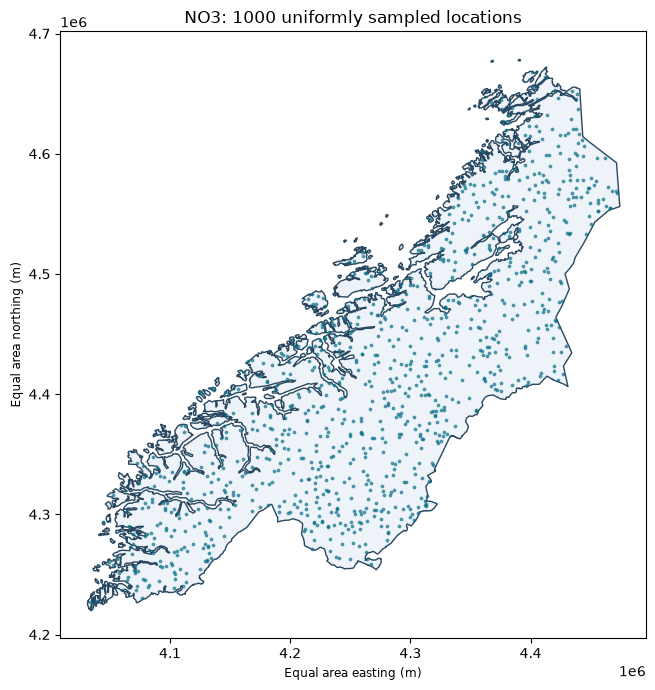

{
  "sources": {
    "electricity": "https://gis3.nve.no/map/rest/services/Mapservices/Omradekonsesjoner/MapServer/8",
    "administrative": "https://gis3.nve.no/map/rest/services/Mapservices/Administrasjon/MapServer/0"
  },
  "seed": 320,
  "points_per_region": 1000,
  "sampling_crs": "EPSG:3035",
  "note": "VASS1=RS+R\u00d8, VASS2=RV, VASS3=RM, VASS4=RN; PRECIP_NORTH=RM+RN is the assignment combined north. All are administrative proxies, not exact catchments. Live NVE metadata distinguishes VASS3 mid and VASS4 north."
}


In [2]:
#inspect saved official polygons and validate all sampled points
regions = gpd.read_file(ROOT / "data/regions/regions.geojson")
points = pd.read_csv(ROOT / "data/regions/points.csv")
display(points.groupby("region").size().rename("sampled locations").to_frame())
assert points.groupby("region").size().eq(1000).all()
no3 = regions.loc[regions.region == REGION]
no3_points = points.loc[points.region == REGION]
locations = gpd.GeoSeries(gpd.points_from_xy(no3_points.longitude, no3_points.latitude), crs=4326)
assert locations.within(no3.geometry.iloc[0]).all()
fig, ax = plt.subplots(figsize=(7, 7))
no3.to_crs(3035).plot(ax=ax, color="#edf3f8", edgecolor="#29485f")
locations.to_crs(3035).plot(ax=ax, markersize=3, color="#086e87", alpha=.6)
ax.set_title("NO3: 1000 uniformly sampled locations")
ax.set_xlabel("Equal area easting (m)"); ax.set_ylabel("Equal area northing (m)")
fig.tight_layout(); plt.show()
print((ROOT / "data/regions/provenance.json").read_text())

## 3. ERA5 download, resource estimate and data quality

`download_region(region, start, end, approved=...)` looks up the saved coordinate list and retrieves at least temperature and precipitation, explicitly selecting ERA5. A full leap year has 8784 hours. Data are checked for correct units, duplicates, complete time coverage and finite values. Each successful request is cached and can be reused after an interruption. A full regional result is only published after every sampled point is represented. The user approved the full NO3 download after receiving a resource estimate. No bulk download is triggered by running this notebook.

Source: [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api), ERA5 / Copernicus, CC BY 4.0. This project computes spatial averages. Reanalysis and neighbouring grid cells are not independent weather-station measurements.

In [3]:
#report the estimate and select only a clearly identified available dataset
print(json.dumps(estimate_download(START, END), indent=2))
try:
    weather, weather_metadata = load_region(REGION, START, END)
    regional_complete = True
except FileNotFoundError:
    weather, weather_metadata = load_region(REGION, START, END, pilot=True)
    regional_complete = False
print(json.dumps(weather_metadata, indent=2))
print("complete regional experiment:", regional_complete)
if not regional_complete:
    display(Markdown("**INCOMPLETE REGIONAL EXPERIMENT: the following weather figures use one pilot location, not the 1000-point mean. Rerun after the full download.**"))
assert len(weather) == 8784 and weather.index.is_unique
assert np.isfinite(weather.to_numpy()).all()
display(weather.describe())
display(weather.head())
if regional_complete and (ROOT / "reports/weather_audit.json").exists():
    display(pd.Series(json.loads((ROOT / "reports/weather_audit.json").read_text())).to_frame("verified result"))

{
  "points": 1000,
  "hours_per_point": 8784,
  "point_hours": 8784000,
  "values": 17568000,
  "float32_MB": 70.27,
  "estimated_transfer_MB": [
    211,
    703
  ],
  "estimated_api_call_units": 26142.9
}
{
  "region": "NO3",
  "start": "2024-01-01",
  "end": "2024-12-31",
  "points": 1000,
  "complete_1000": true,
  "model": "era5",
  "timezone": "UTC",
  "coordinates_hash": "e317ed1283d1",
  "source": "https://archive-api.open-meteo.com/v1/archive",
  "point_cache": "NO3_2024-01-01_2024-12-31_e317ed1283d1"
}
complete regional experiment: True


,temperature_2m,precipitation
count,8784.000000,8784.000000
mean,4.238217,0.197329
std,7.659723,0.283680
min,-16.737800,0.000000
25%,-0.817300,0.009700
50%,3.846300,0.084200
75%,10.041925,0.273600
max,24.328100,3.376700


,temperature_2m,precipitation
timestamp,,
2024-01-01 00:00:00+00:00,-6.0342,0.0059
2024-01-01 01:00:00+00:00,-6.1923,0.0050
2024-01-01 02:00:00+00:00,-6.1487,0.0050
2024-01-01 03:00:00+00:00,-6.1830,0.0050
2024-01-01 04:00:00+00:00,-6.1134,0.0048


,verified result
region,NO3
points,1000
hours,8784
point_hours,8784000
scalar_values,17568000
missing_values,0
unique_returned_grid_cells,222
max_recomputed_mean_error,0.0
temperature_range_c,"[-16.7378, 24.3281]"
precipitation_range_mm_h,"[0.0, 3.3767]"


## 4. Precipitation outliers: DCT high pass and robust SPC

An orthonormal DCT-II represents the original hourly precipitation. Coefficient k has frequency k/(2 N Δt). Frequencies at or below 1/30 days form the smooth baseline; subtracting it gives the high-pass residuals. The entire year's residual median and Gaussian-consistent median absolute deviation (MAD) define robust limits at median ±3 MAD. Adding the baseline yields limits on the **original precipitation scale**. Only original precipitation, limits and contrasting outliers are plotted; residual/SATV values are not plotted.

The assignment's temperature wording in this precipitation section is interpreted as seasonally adjusted precipitation variations. Rainfall is skewed, autocorrelated and often zero, so these are descriptive control limits, not calibrated Gaussian probabilities. Zero MAD is explicitly reported. Negative lower limits are retained to show the mathematical limits and do not imply physically negative rain. Cutoff and sigma multiplier are configurable.

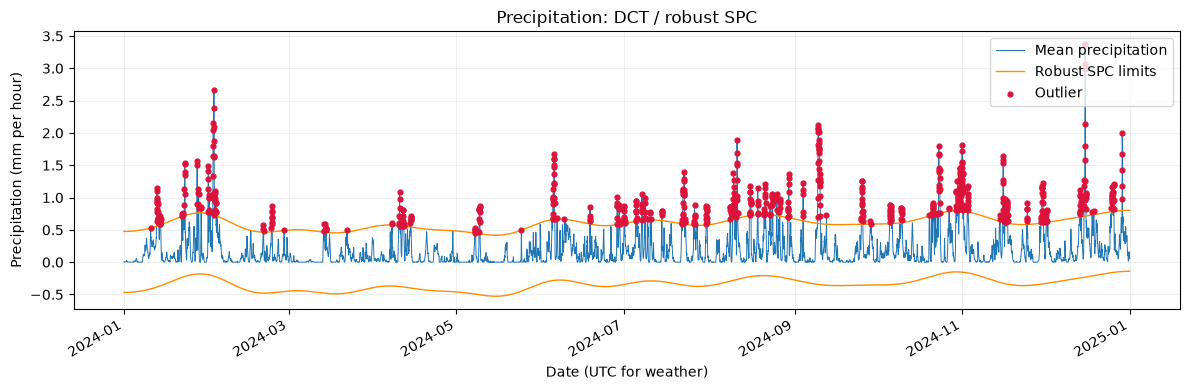

{'observations': 8784, 'outliers': 633, 'fraction': 0.07206284153005464, 'robust_sigma': 0.15724150253350086, 'zero_scale': False}


,value,baseline,lower,upper,outlier
timestamp,,,,,
2024-01-10 17:00:00+00:00,0.5295,0.123626,-0.414865,0.528584,True
2024-01-12 21:00:00+00:00,0.6326,0.151383,-0.387108,0.556341,True
2024-01-12 22:00:00+00:00,0.7686,0.151971,-0.386520,0.556929,True
2024-01-12 23:00:00+00:00,0.9322,0.152560,-0.385930,0.557519,True
2024-01-13 00:00:00+00:00,1.1437,0.153152,-0.385339,0.558110,True
2024-01-13 01:00:00+00:00,1.1075,0.153746,-0.384745,0.558704,True
2024-01-13 02:00:00+00:00,0.9133,0.154341,-0.384149,0.559300,True
2024-01-13 03:00:00+00:00,0.8162,0.154939,-0.383552,0.559897,True
2024-01-13 04:00:00+00:00,0.9598,0.155538,-0.382953,0.560496,True


In [4]:
#analyse precipitation and display the actual flagged observations
CUTOFF_DAYS, N_SIGMA = 30, 3
fig, spc_table, spc_summary = spc_analysis(weather.precipitation, CUTOFF_DAYS, N_SIGMA)
plt.show()
print(spc_summary)
display(spc_table.loc[spc_table.outlier].head(20))
(ROOT / "reports/figures").mkdir(parents=True, exist_ok=True)
fig.savefig(ROOT / "reports/figures/precipitation_spc.png", dpi=160, bbox_inches="tight")
spc_table.to_csv(ROOT / "reports/spc_results.csv")

## 5. Temperature anomalies: Local Outlier Factor

LOF compares local neighbour densities using two standardized features: temperature and its hourly change. The first change is defined as zero. Defaults are 48 neighbours and 1% contamination. This can highlight unusual temperatures or rapid changes relative to the data's density. Contamination is a modelling assumption; detected anomalies are not necessarily errors. The model is descriptive and has no training/test claim or causal interpretation.

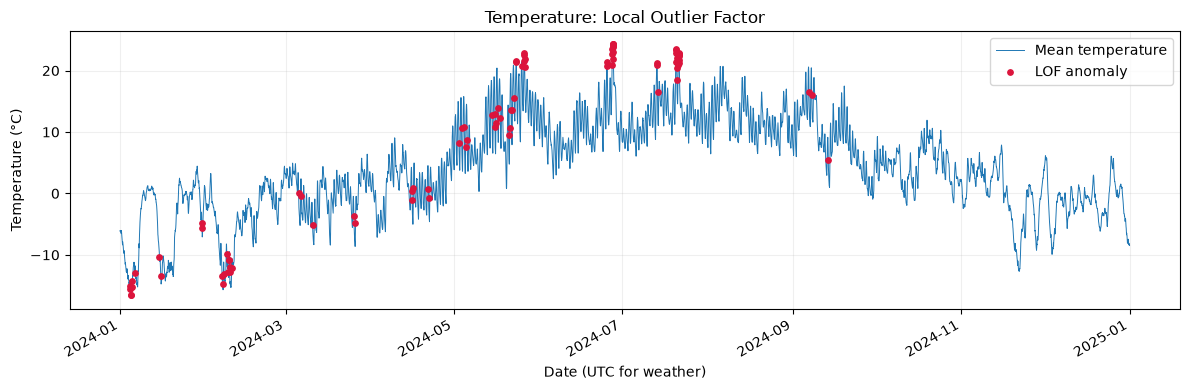

{'observations': 8784, 'outliers': 88, 'fraction': 0.010018214936247723}


,value,lof_score,outlier
timestamp,,,
2024-02-09 16:00:00+00:00,-11.9860,2.124686,True
2024-02-07 16:00:00+00:00,-13.1029,2.072824,True
2024-02-09 15:00:00+00:00,-10.8009,2.069047,True
2024-05-16 20:00:00+00:00,13.9061,2.032413,True
2024-03-25 18:00:00+00:00,-3.7058,1.882231,True
2024-04-21 19:00:00+00:00,0.7603,1.872662,True
2024-05-15 20:00:00+00:00,12.9215,1.870787,True
2024-05-22 06:00:00+00:00,13.6301,1.803361,True
2024-05-21 06:00:00+00:00,10.6111,1.778859,True


In [5]:
#identify temperature anomalies using the same complete hourly time index
fig, lof_table, lof_summary = lof_analysis(weather.temperature_2m, contamination=.01, n_neighbors=48)
plt.show()
print(lof_summary)
display(lof_table.loc[lof_table.outlier].sort_values("lof_score", ascending=False).head(20))
fig.savefig(ROOT / "reports/figures/temperature_lof.png", dpi=160, bbox_inches="tight")
lof_table.to_csv(ROOT / "reports/lof_results.csv")

### Parameter sensitivity

Outlier counts depend on modelling choices. The following checks vary the DCT cutoff and the assumed LOF contamination while holding other defaults fixed. More flags do not establish worse data quality; they show sensitivity to the definition of an unusual observation.

In [6]:
#compare parameter choices without displaying additional duplicate figures
sensitivity = []
for cutoff in [7, 30, 90]:
    figure, table, summary = spc_analysis(weather.precipitation, cutoff_days=cutoff, n_sigma=3)
    plt.close(figure)
    sensitivity.append({"method": "spc", "parameter": f"cutoff {cutoff} days", "flagged": summary["outliers"]})
for fraction in [.005, .01, .02]:
    figure, table, summary = lof_analysis(weather.temperature_2m, contamination=fraction, n_neighbors=48)
    plt.close(figure)
    sensitivity.append({"method": "lof", "parameter": f"contamination {100*fraction:g}%", "flagged": summary["outliers"]})
display(pd.DataFrame(sensitivity))

,method,parameter,flagged
0,spc,cutoff 7 days,640
1,spc,cutoff 30 days,633
2,spc,cutoff 90 days,725
3,lof,contamination 0.5%,44
4,lof,contamination 1%,88
5,lof,contamination 2%,176


## 6. Reservoir filling: prepare a regular weekly series

Use one reservoir area's filling fraction, not an average of overlapping national and regional statistics. The included NVE snapshot makes the analysis reproducible offline; the Streamlit app continues to retrieve current data from NVE. Missing weeks and duplicate timestamps are rejected rather than silently interpolated. Several years are needed to distinguish annual seasonality from trend.

In [7]:
#select the same no3 electricity area and inspect weekly coverage
reservoir = pd.read_parquet(ROOT / "data/reservoir.parquet")
filling = weekly_series(reservoir, area_type="EL", area=3)
print("weekly observations:", len(filling))
print("time interval:", filling.index.min(), filling.index.max())
print("step sizes:", filling.index.to_series().diff().dropna().value_counts().to_dict())
display(filling.describe())

weekly observations: 1660
time interval: 1995-01-08 00:00:00 2026-10-25 00:00:00
step sizes: {Timedelta('7 days 00:00:00'): 1659}


count    1660.000000
mean        0.597635
std         0.236924
min         0.107109
25%         0.391493
50%         0.640104
75%         0.801169
max         0.985538
Name: fill_level, dtype: float64

## 7. Seasonal trend decomposition using LOESS

STL separates observed filling fraction into trend, seasonal component and residual. Use annual period 52 weekly observations, seasonal smoother 13, trend smoother 105 and robust fitting by default. Smoothers must be odd; trend must exceed the seasonal period. A 52-week year approximates the true calendar year. Robust fitting reduces the influence of exceptional weeks without proving that they are erroneous.

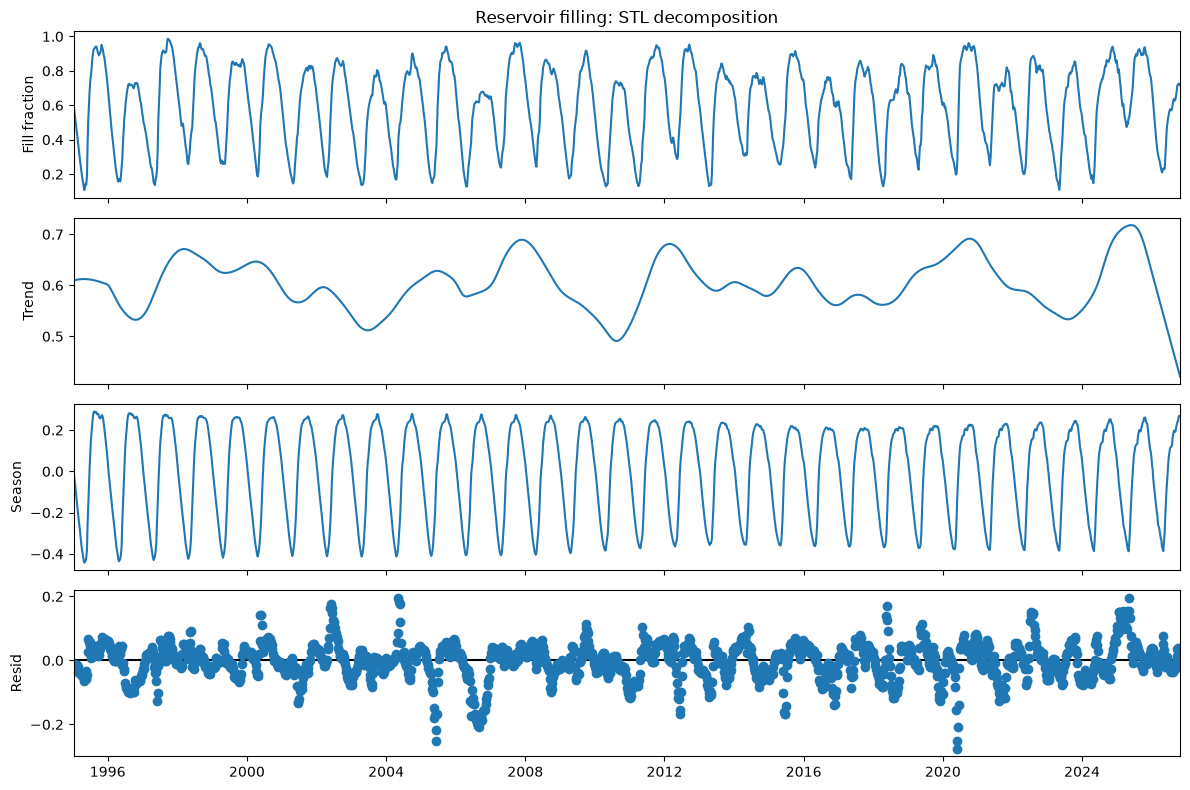

seasonal range: 0.732700354123887
residual standard deviation: 0.05661886825485383


In [8]:
#decompose the entire regular weekly series and verify reconstruction
fig, stl_result = stl_analysis(filling, seasonal=13, trend=105, robust=True)
plt.show()
assert np.allclose(stl_result.trend + stl_result.seasonal + stl_result.resid, filling)
fig.savefig(ROOT / "reports/figures/reservoir_stl.png", dpi=160, bbox_inches="tight")
print("seasonal range:", float(stl_result.seasonal.max() - stl_result.seasonal.min()))
print("residual standard deviation:", float(stl_result.resid.std()))

## 8. Spectrogram of the same filling series

A Hann-window spectrogram uses 156 weekly samples per window with 130 samples overlap. Each segment is linearly detrended. Frequencies are cycles per 52-week year; 1 cycle/year represents annual variation. The frequency resolution is 52/156 = 1/3 cycles/year. Longer windows improve frequency resolution while reducing temporal localisation. Colour represents log power density; a small floor is used only to display logarithms. The plot focuses on 0–6 cycles/year; the full computed spectrum extends to the weekly Nyquist frequency of 26 cycles/year. Only complete windows are shown, so their centres do not reach the endpoints.

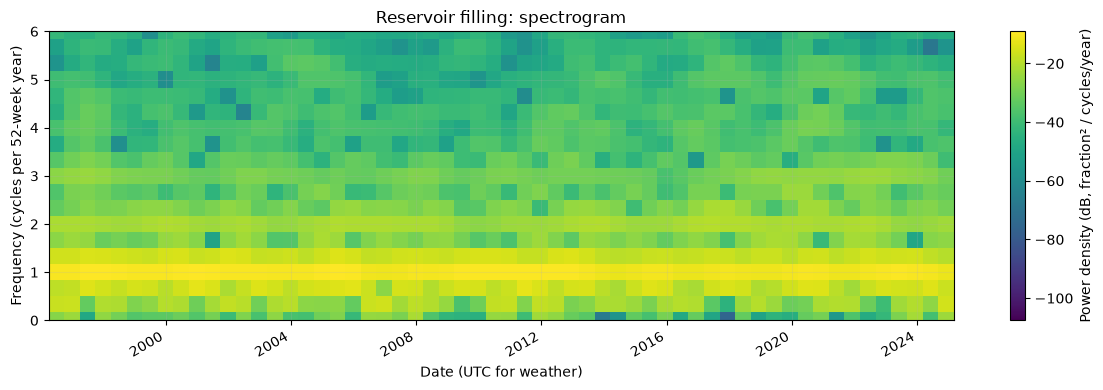

dominant nonzero frequency: 1.0 cycles per year


In [9]:
#use exactly the same weekly filling series as the stl analysis
fig, spectrum = spectrogram_analysis(filling, window=156, overlap=130)
plt.show()
fig.savefig(ROOT / "reports/figures/reservoir_spectrogram.png", dpi=160, bbox_inches="tight")
nonzero = spectrum["frequency"] > 0
frequency = spectrum["frequency"][nonzero]
mean_power = spectrum["power"][nonzero].mean(axis=1)
print("dominant nonzero frequency:", float(frequency[mean_power.argmax()]), "cycles per year")

## 9. Function tests and scientific validation

The test suite checks known annual periodicity, STL reconstruction and seasonal recovery, injected SPC/LOF anomalies, constant signals, invalid parameters, missing timestamps, deterministic area sampling, polygon containment, download approval, cache reuse and rate-limit handling. Streamlit tests exercise date filtering, comparison controls and the new analysis pages. These tests complement scientific interpretation; they do not prove all real-weather flags are meaningful.

In [10]:
#run the local test suite without making external database writes
import subprocess
check = subprocess.run([sys.executable, "-m", "pytest", "-q"], cwd=ROOT, capture_output=True, text=True)
print(check.stdout)
if check.returncode:
    print(check.stderr)
assert check.returncode == 0

......................................                                   [100%]
=============================== warnings summary ===============================
tests/test_streamlit.py::test_plot_default_and_comparison
tests/test_streamlit.py::test_existing_electricity_page_with_database_fixture
  /Users/daniaromar/Documents/ChatGPT/IND320/.venv/lib/python3.11/site-packages/streamlit/elements/lib/built_in_chart_utils.py:620: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
  See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
    df.reset_index(inplace=True)  # noqa: PD002

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
38 passed, 2 warnings in 6.22s



## 10. Interpretation of the actual results

In [11]:
#summarize computed results while keeping completion status explicit
status = "1000 point regional mean" if regional_complete else "single point pilot only"
display(Markdown(f"""The weather results above use **{status}**. SPC flags **{spc_summary['outliers']}** of {len(weather)} hourly observations with a 30 day baseline and three robust sigmas. LOF flags **{lof_summary['outliers']}** observations with the assumed 1% contamination. These methods answer different questions: SPC measures departures from a smooth precipitation baseline, while LOF identifies locally unusual temperature states or changes. Neither establishes a data error or physical cause.

The reservoir series contains **{len(filling)} weekly observations**. STL reconstruction was verified numerically. The strongest nonzero average spectral frequency is **{frequency[mean_power.argmax()]:.3f} cycles per year**. This describes a frequency component rather than a causal driver. Inspect the decomposition and changes in spectral power alongside the original data.

Regional averaging smooths local extremes, and repeated ERA5 grid cells make sampled points spatially dependent. Results depend on cutoff, neighbours, assumed contamination and smoothing settings; these are exposed in Streamlit for sensitivity analysis."""))

The weather results above use **1000 point regional mean**. SPC flags **633** of 8784 hourly observations with a 30 day baseline and three robust sigmas. LOF flags **88** observations with the assumed 1% contamination. These methods answer different questions: SPC measures departures from a smooth precipitation baseline, while LOF identifies locally unusual temperature states or changes. Neither establishes a data error or physical cause.

The reservoir series contains **1660 weekly observations**. STL reconstruction was verified numerically. The strongest nonzero average spectral frequency is **1.000 cycles per year**. This describes a frequency component rather than a causal driver. Inspect the decomposition and changes in spectral power alongside the original data.

Regional averaging smooths local extremes, and repeated ERA5 grid cells make sampled points spatially dependent. Results depend on cutoff, neighbours, assumed contamination and smoothing settings; these are exposed in Streamlit for sensitivity analysis.

## 11. Streamlit integration and Part 2 feedback

The existing Streamlit URL is retained. The Reservoir Data date interval filters overview sparklines, detailed rows and CSV export together. Shared area selection connects reservoir and weather pages. Optional comparisons and separate plots for different units improve readability. New pages provide `st.tabs()` for STL/Spectrogram and SPC/LOF, with user controls, figures and outlier summaries. The existing electricity page, MongoDB secrets handling and NVE API connection remain available. A single-point request is explicit; bulk weather jobs run locally with approval and resumable caching.

## 12. Development log

This technical development log was prepared with AI assistance from the recorded implementation work. It records the technical work performed and distinguishes verification from remaining submission actions.

Part 3 extends the existing reservoir and electricity application with regional weather data and time series analysis. The first step was to inspect the Part 1 and Part 2 notebooks, Python files and Git history. The existing work already included direct NVE access, an ENTSO-E processing pipeline using Spark and Cassandra, and a MongoDB-backed electricity page. These components were retained. A separate Part 3 development branch was created, and files changed during this implementation were backed up. The remote history confirmed the earlier Part 2 merge into main.

The geographical workflow retrieves official NVE polygons, retains their provenance and exports shapefiles. Locations are sampled reproducibly in an equal-area projection before conversion to latitude and longitude. Current NVE metadata distinguishes middle and northern VASS areas, which differs from the assignment's combined north wording. Both the mapping and its limitations are documented instead of treating administrative boundaries as exact catchments.

Weather retrieval uses the historical Open-Meteo endpoint with the ERA5 model selected explicitly. The downloader checks units, hourly coverage, duplicates and missing values. Each successful point is cached separately, allowing interrupted downloads to resume. Resource use was estimated before the full NO3 download was approved. After validating a single-point pilot, the complete NO3 experiment was downloaded: 1000 locations with 8784 hourly observations each. An hourly quota pause was respected, and the last 43 locations were retrieved after the next hourly reset. The regional mean was independently checked against all cached point series.

Four analysis functions were implemented for reuse in the notebook and Streamlit. Precipitation outliers use a DCT baseline and robust residual control limits. Temperature anomalies use Local Outlier Factor on standardized temperature and hourly changes. Weekly reservoir filling is analysed with robust STL and a Hann-window spectrogram. Synthetic signals and injected anomalies test meaningful scientific properties, including seasonal recovery, reconstruction and the expected annual spectral peak.

The Streamlit work incorporates feedback from Part 2. The Reservoir Data page now filters its overview, detailed dataset and export by the same date interval. Shared area selection connects reservoir and weather analyses. Optional area comparison and separate variable panels improve readability. New tabbed pages expose analysis parameters, plots and summaries. The original app address is retained, and bulk weather retrieval is controlled locally rather than triggered by ordinary page interactions.

Finally, the project gains organised notebook and report folders, installation instructions, a delivery checklist and a screencast outline. Automated checks cover data preparation, numerical analyses, downloader behaviour and Streamlit interactions. Final submission still requires checking complete regional results, reviewing this log, recording the video and approving the merge and deployment.

## 13. AI usage

Codex assisted with repository inspection, implementation planning, Python programming, API documentation research, test design, Streamlit integration, notebook preparation and technical writing for Part 3. The user explicitly approved implementation, package installation and local testing, and separately approved the large NO3 weather download after receiving an estimate.

Generated code was exercised locally with numerical tests, deterministic synthetic signals, real NVE data and an ERA5 pilot. Test records distinguish successful checks from pending external work. The existing Spark, Cassandra and MongoDB pipeline was preserved rather than rerun with database writes. Its historical outputs are not presented as newly verified database results.

The development log is an AI-assisted technical draft based on actions performed during implementation. It must be reviewed by the student and supplemented with personal reflections. AI assistance does not replace interpretation of scientific results, checking the assignment's geographic ambiguity, or responsibility for the final submission. No claim is made that the student has already independently reviewed all generated work.

No credentials are included in the new deliverables. The user subsequently authorized the necessary publication and merge steps. The final delivery status records which were completed; the video remains for the student to record. New and edited Python comment tokens follow the user's English lowercase style without hyphens.

## 14. Submission and sources

Review the development log and geographic assumptions, run this notebook on the complete regional dataset, inspect the PDF export and record the five minute video. The repository must show a merge from the Part 3 development branch into main. Update the existing app rather than creating a new URL. The video link must be accessible to reviewers.

- NVE reservoir source: https://www.nve.no/energi/analyser-og-statistikk/om-magasinstatistikken/
- NVE area metadata: https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOmr%C3%A5der
- Electricity polygons: https://gis3.nve.no/map/rest/services/Mapservices/Omradekonsesjoner/MapServer/8
- Administrative polygons: https://gis3.nve.no/map/rest/services/Mapservices/Administrasjon/MapServer/0
- ERA5 API and attribution: https://open-meteo.com/en/docs/historical-weather-api
- API quotas: https://open-meteo.com/en/pricing

The full methodological record is in `reports/ASSUMPTIONS.md`.

## Appendix: shared function implementations

These are the actual functions imported and tested above. Printing their source keeps the PDF reviewable without duplicating production logic in the notebook. Their imports and supporting helpers are maintained in the accompanying repository modules. Printing source does not launch any extra downloads.

In [12]:
#include the actual reusable implementations in the executed report
import inspect
from src.weather import download_point, download_region
from src.geography import sample_polygon
for function in [sample_polygon, download_point, download_region, spc_analysis, lof_analysis, stl_analysis, spectrogram_analysis]:
    print(function.__name__)
    print(inspect.getsource(function))

sample_polygon
def sample_polygon(geometry, count=1000, seed=320, original_wgs84=None):
    """uniform area in epsg:3035 (equal area), then convert to lon/lat."""
    if count<1 or geometry.is_empty:raise ValueError('Nonempty polygon and positive count required.')
    rng=np.random.default_rng(seed);xmin,ymin,xmax,ymax=geometry.bounds
    points=[]
    for _ in range(10000):
        x=rng.uniform(xmin,xmax,max(1000,count*2));y=rng.uniform(ymin,ymax,len(x))
        inside=contains_xy(geometry,x,y)
        accepted_x,accepted_y=x[inside],y[inside]
        if original_wgs84 is not None:
            #verify containment after transformation because polygon edges change projection
            candidate=gpd.GeoSeries(gpd.points_from_xy(accepted_x,accepted_y),crs=3035).to_crs(4326)
            valid=contains_xy(original_wgs84,candidate.x.to_numpy(),candidate.y.to_numpy())
            accepted_x,accepted_y=accepted_x[valid],accepted_y[valid]
        points.extend(zip(accepted_x,accepted_y))
   